<a href="https://colab.research.google.com/github/aansikkaw/Customer-Segmentation-Churn-Prediction-System/blob/main/Customer_Segmentation_%26_Churn_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation & Churn Prediction (Telco)

This notebook segments customers with K-Means and predicts churn with Logistic Regression, using a Decision Tree as a baseline.

**Data:** the public *Telco Customer Churn* dataset (7,043 customers, 21 columns, file `WA_Fn-UseC_-Telco-Customer-Churn.csv`). It is not stored in this repo. Download it (for example from Kaggle, "Telco Customer Churn") and place it next to this notebook or in a `data/` folder.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, roc_curve, roc_auc_score,
                             silhouette_score, precision_score, recall_score)

RANDOM_STATE = 42

## 1. Load and clean the data

In [2]:
CANDIDATES = [
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv",   # Google Colab upload location
]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Download the Telco Customer Churn CSV and place it next to this notebook "
                            "or in a data/ folder (see the README).")

df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)

# TotalCharges is text in the raw file because 11 rows are blank.
blank = df["TotalCharges"].astype(str).str.strip().eq("")
print("Blank TotalCharges rows:", int(blank.sum()), "| their tenure values:", [int(v) for v in sorted(df.loc[blank, "tenure"].unique())])
# Every blank row has tenure 0 (customers not yet billed), so 0 is the correct value, not a statistical guess.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

Rows, columns: (7043, 21)
Blank TotalCharges rows: 11 | their tenure values: [0]


In [3]:
print("Missing values per column (after fix):", int(df.isnull().sum().sum()))
print("Duplicate customer IDs:", int(df["customerID"].duplicated().sum()))
print("Churn rate: {:.1%}".format((df["Churn"] == "Yes").mean()))
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

Missing values per column (after fix): 0
Duplicate customer IDs: 0
Churn rate: 26.5%


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


## 2. Exploratory analysis

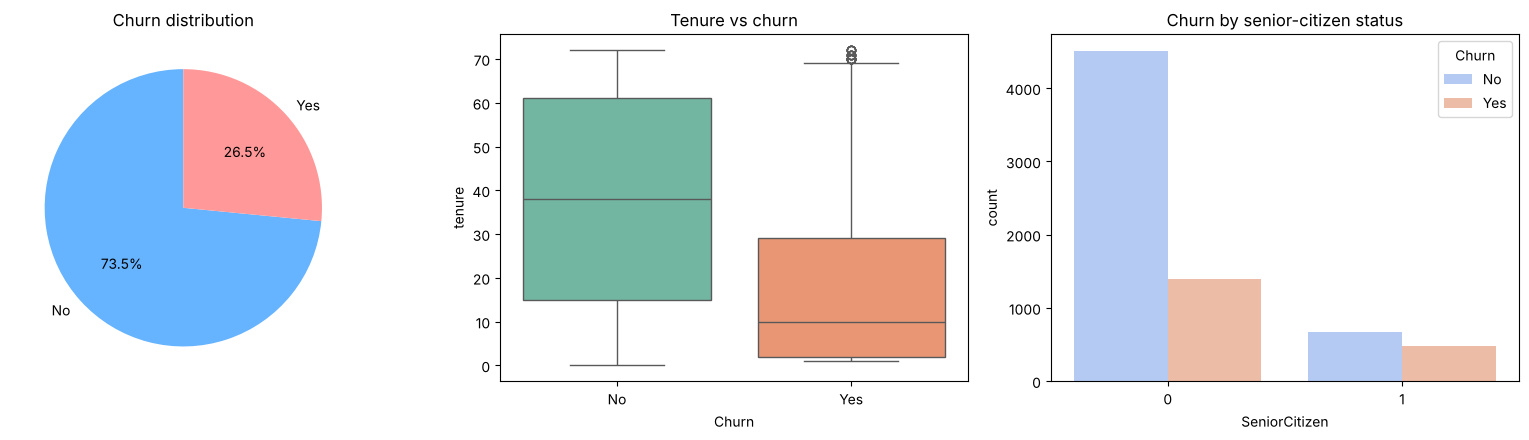

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
df["Churn"].value_counts().plot.pie(autopct="%1.1f%%", colors=["#66b3ff", "#ff9999"], startangle=90, ax=axes[0])
axes[0].set_title("Churn distribution"); axes[0].set_ylabel("")
sns.boxplot(x="Churn", y="tenure", data=df, hue="Churn", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Tenure vs churn")
sns.countplot(x="SeniorCitizen", hue="Churn", data=df, palette="coolwarm", ax=axes[2])
axes[2].set_title("Churn by senior-citizen status")
plt.tight_layout(); plt.show()

## 3. Customer segmentation (K-Means)

K-Means uses distance, so the three numeric features are standardised first. `TotalCharges` is almost exactly `tenure x MonthlyCharges`, so tenure carries extra weight in the clusters. The model is fitted on all customers; K-Means never sees the churn label, but this means the segments are not computed from the training split only.

First compare several values of k.

 k  inertia  silhouette
 2     9712       0.480
 3     6186       0.451
 4     4148       0.472
 5     3111       0.444
 6     2563       0.440


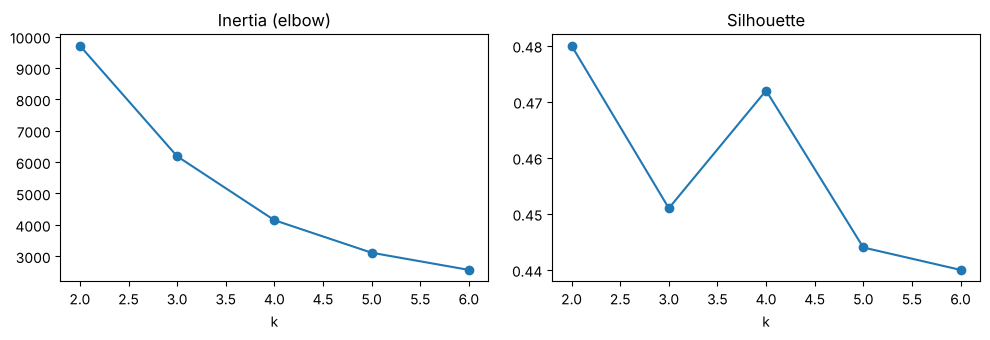

In [5]:
features_cluster = df[["tenure", "MonthlyCharges", "TotalCharges"]]
scaled_features = StandardScaler().fit_transform(features_cluster)

rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(scaled_features)
    rows.append({"k": k, "inertia": round(km.inertia_), "silhouette": round(silhouette_score(scaled_features, km.labels_), 3)})
k_table = pd.DataFrame(rows)
print(k_table.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(k_table["k"], k_table["inertia"], marker="o"); ax[0].set_title("Inertia (elbow)"); ax[0].set_xlabel("k")
ax[1].plot(k_table["k"], k_table["silhouette"], marker="o"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

**Choice of k = 3.** The elbow is not sharp, and silhouette is slightly higher for k = 2 and k = 4. Three segments were chosen because they are easy to act on, and (below) they separate churn behaviour clearly. This is a business choice, not a statistical optimum.

In [6]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
df["Customer_Segment"] = kmeans.fit_predict(scaled_features)

profile = df.groupby("Customer_Segment").agg(
    customers=("Customer_Segment", "size"),
    avg_tenure=("tenure", "mean"),
    avg_monthly=("MonthlyCharges", "mean"),
    avg_total=("TotalCharges", "mean"),
    churn_rate=("Churn", lambda s: (s == "Yes").mean()),
).round(3)

# Cluster numbers are arbitrary, so name each segment from its profile instead of hard-coding labels.
vip = profile["avg_tenure"].idxmax()                                   # longest tenure
rest = [c for c in profile.index if c != vip]
new_high = profile.loc[rest, "avg_monthly"].idxmax()                    # newer, higher monthly bill
budget = [c for c in rest if c != new_high][0]                          # lowest monthly bill
segment_names = {vip: "VIP / Core Revenue", new_high: "High-Risk New Users", budget: "Budget-Conscious"}
profile["segment"] = profile.index.map(segment_names)
profile

,customers,avg_tenure,avg_monthly,avg_total,churn_rate,segment
Customer_Segment,,,,,,
0,2154,29.498,26.573,809.420,0.123,Budget-Conscious
1,2200,58.560,89.698,5246.126,0.154,VIP / Core Revenue
2,2689,13.247,74.951,1030.569,0.471,High-Risk New Users


In [7]:
print("BUSINESS READ-OUT (numbers come from the table above)")
for seg, row in profile.sort_values("churn_rate", ascending=False).iterrows():
    print(f"- Segment {seg}, {row['segment']}: {int(row['customers'])} customers, "
          f"avg tenure {row['avg_tenure']:.0f} months, ${row['avg_monthly']:.0f}/month, churn {row['churn_rate']:.0%}")
print()
print("Suggested actions (hypotheses to test, not results):")
print("- High-Risk New Users: onboarding support and early-life offers.")
print("- VIP / Core Revenue: loyalty rewards and account contact; avoid blanket discounts.")
print("- Budget-Conscious: low-cost automated nurturing and contract-extension offers.")

BUSINESS READ-OUT (numbers come from the table above)
- Segment 2, High-Risk New Users: 2689 customers, avg tenure 13 months, $75/month, churn 47%
- Segment 1, VIP / Core Revenue: 2200 customers, avg tenure 59 months, $90/month, churn 15%
- Segment 0, Budget-Conscious: 2154 customers, avg tenure 29 months, $27/month, churn 12%

Suggested actions (hypotheses to test, not results):
- High-Risk New Users: onboarding support and early-life offers.
- VIP / Core Revenue: loyalty rewards and account contact; avoid blanket discounts.
- Budget-Conscious: low-cost automated nurturing and contract-extension offers.


## 4. Churn prediction

Same 80/20 split and seed as the reported results (`random_state=42`, not stratified). Cross-validation below checks that the numbers are not an artefact of this one split.

In [8]:
df_model = df.drop(columns=["customerID"])
df_encoded = pd.get_dummies(df_model, drop_first=True, dtype=int)

X = df_encoded.drop("Churn_Yes", axis=1)
y = df_encoded["Churn_Yes"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler()                      # fitted on the training split only
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train {:.1%} | test {:.1%}".format(y_train.mean(), y_test.mean()))
print("Majority-class baseline accuracy on test: {:.1%}".format(1 - y_test.mean()))

Train: (5634, 31) | Test: (1409, 31)
Churn rate train 26.6% | test 26.5%
Majority-class baseline accuracy on test: 73.5%


In [9]:
log_reg = LogisticRegression(max_iter=10000, solver="lbfgs").fit(X_train_scaled, y_train)
log_probs = log_reg.predict_proba(X_test_scaled)[:, 1]
log_preds = log_reg.predict(X_test_scaled)

dtree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(X_train, y_train)
tree_probs = dtree.predict_proba(X_test)[:, 1]
tree_preds = dtree.predict(X_test)

print("LOGISTIC REGRESSION"); print(classification_report(y_test, log_preds, digits=3))
print("DECISION TREE (max_depth=5)"); print(classification_report(y_test, tree_preds, digits=3))

summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree (depth 5)"],
    "Accuracy": [(log_preds == y_test).mean(), (tree_preds == y_test).mean()],
    "Churn precision": [precision_score(y_test, log_preds), precision_score(y_test, tree_preds)],
    "Churn recall": [recall_score(y_test, log_preds), recall_score(y_test, tree_preds)],
    "ROC-AUC": [roc_auc_score(y_test, log_probs), roc_auc_score(y_test, tree_probs)],
}).round(3)
summary

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0      0.860     0.900     0.879      1036
           1      0.680     0.592     0.633       373

    accuracy                          0.818      1409
   macro avg      0.770     0.746     0.756      1409
weighted avg      0.812     0.818     0.814      1409

DECISION TREE (max_depth=5)
              precision    recall  f1-score   support

           0      0.857     0.871     0.864      1036
           1      0.625     0.598     0.611       373

    accuracy                          0.798      1409
   macro avg      0.741     0.734     0.737      1409
weighted avg      0.796     0.798     0.797      1409



,Model,Accuracy,Churn precision,Churn recall,ROC-AUC
0,Logistic Regression,0.818,0.680,0.592,0.862
1,Decision Tree (depth 5),0.798,0.625,0.598,0.837


### Robustness check: stratified 5-fold cross-validation

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "roc_auc": "roc_auc"}
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000)),
    "Decision Tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
}
cv_rows = []
for name, model in models.items():
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    cv_rows.append({"Model": name, **{m: f"{res['test_'+m].mean():.3f} +/- {res['test_'+m].std():.3f}" for m in scoring}})
pd.DataFrame(cv_rows)

,Model,accuracy,precision,recall,roc_auc
0,Logistic Regression,0.804 +/- 0.010,0.657 +/- 0.021,0.548 +/- 0.030,0.845 +/- 0.013
1,Decision Tree (depth 5),0.792 +/- 0.012,0.638 +/- 0.027,0.500 +/- 0.051,0.824 +/- 0.014


### Ablation: is the K-Means segment useful as a classifier feature?

The segment is built from `tenure`, `MonthlyCharges` and `TotalCharges`, which are already in the model, and it is coded 0/1/2 although the numbers have no order. Check whether it adds anything.

In [11]:
X_no_seg = X.drop(columns="Customer_Segment")
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_no_seg, y, test_size=0.2, random_state=RANDOM_STATE)
sc_a = StandardScaler()
lr_a = LogisticRegression(max_iter=10000).fit(sc_a.fit_transform(Xa_train), ya_train)
auc_a = roc_auc_score(ya_test, lr_a.predict_proba(sc_a.transform(Xa_test))[:, 1])
print(f"Logistic Regression ROC-AUC with segment feature:    {roc_auc_score(y_test, log_probs):.3f}")
print(f"Logistic Regression ROC-AUC without segment feature: {auc_a:.3f}")

Logistic Regression ROC-AUC with segment feature:    0.862
Logistic Regression ROC-AUC without segment feature: 0.862


## 5. Choosing the alert threshold

A higher threshold gives a shorter, more accurate list but misses more churners. The right value depends on what a retention offer costs compared with what a kept customer is worth.

In [12]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    flagged = log_probs >= t
    rows.append({"threshold": t, "customers_flagged": int(flagged.sum()),
                 "precision": round(precision_score(y_test, flagged), 3),
                 "recall": round(recall_score(y_test, flagged), 3)})
threshold_table = pd.DataFrame(rows)
print(f"(test set: {len(y_test)} customers, {int(y_test.sum())} churners)")
threshold_table

(test set: 1409 customers, 373 churners)


,threshold,customers_flagged,precision,recall
0,0.3,540,0.554,0.802
1,0.4,434,0.601,0.700
2,0.5,325,0.680,0.592
3,0.6,208,0.750,0.418
4,0.7,92,0.826,0.204


## 6. Action list for high-risk customers

This scores the **test split only** (1,409 customers), so it is a demonstration of the output, not a full customer list. In production the model would score every active customer on a schedule, and a randomised holdout would test whether the retention actions work.

In [13]:
HIGH_RISK = 0.70
action_df = pd.DataFrame({
    "customer_index": X_test.index,
    "churn_probability": log_probs,
    "segment": X_test["Customer_Segment"].map(segment_names).values,
    "actual_churn": y_test.values,
})
high_risk = action_df[action_df["churn_probability"] >= HIGH_RISK].sort_values("churn_probability", ascending=False)

print(f"Customers at or above {HIGH_RISK:.0%} churn probability: {len(high_risk)} of {len(action_df)}")
print("Of these, share who actually churned: {:.1%}".format(high_risk["actual_churn"].mean()))
print(high_risk["segment"].value_counts().to_string())
high_risk.head(10).round(3)

Customers at or above 70% churn probability: 92 of 1409
Of these, share who actually churned: 82.6%
segment
High-Risk New Users    89
Budget-Conscious        3


,customer_index,churn_probability,segment,actual_churn
1109,2208,0.842,High-Risk New Users,1
365,1410,0.841,High-Risk New Users,1
1106,4800,0.839,High-Risk New Users,1
680,2577,0.822,High-Risk New Users,1
456,3346,0.818,High-Risk New Users,0
418,2184,0.813,High-Risk New Users,1
674,2191,0.804,High-Risk New Users,1
285,585,0.801,High-Risk New Users,1
188,3078,0.798,High-Risk New Users,1
417,534,0.794,High-Risk New Users,1


## 7. Model diagnostics

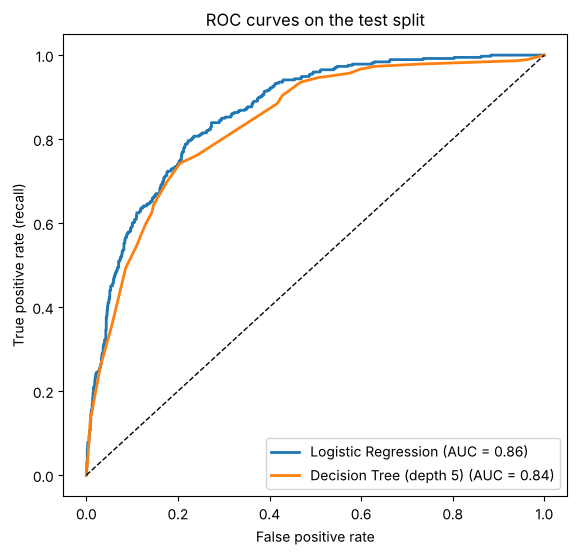

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, probs in [("Logistic Regression", log_probs), ("Decision Tree (depth 5)", tree_probs)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, probs):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test split"); ax.legend(loc="lower right")
plt.show()

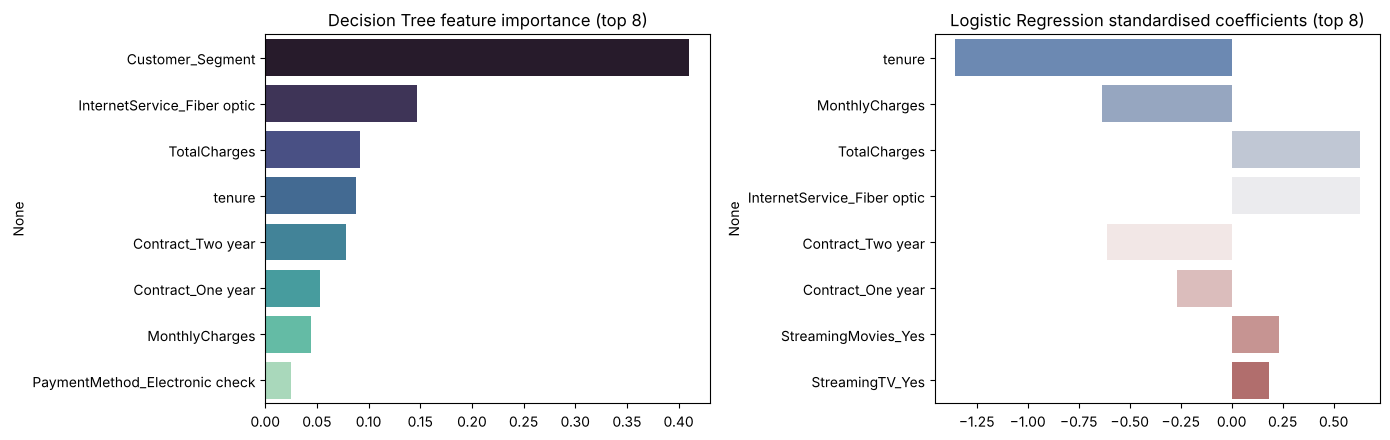

In [15]:
tree_imp = pd.Series(dtree.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
lr_coef = pd.Series(log_reg.coef_[0], index=X.columns)
lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).head(8).index)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=tree_imp.values, y=tree_imp.index, hue=tree_imp.index, palette="mako", legend=False, ax=ax[0])
ax[0].set_title("Decision Tree feature importance (top 8)")
sns.barplot(x=lr_top.values, y=lr_top.index, hue=lr_top.index, palette="vlag", legend=False, ax=ax[1])
ax[1].set_title("Logistic Regression standardised coefficients (top 8)")
plt.tight_layout(); plt.show()

**Reading the charts.** The tree's top split is the K-Means segment, because it summarises tenure and charges in one column. In Logistic Regression, `tenure` has the largest standardised coefficient (negative: longer tenure, lower churn). `tenure`, `MonthlyCharges` and `TotalCharges` are strongly related, so individual coefficients are unstable and show association, not cause.

## Limitations and next steps

- One public dataset, one split for the headline numbers (cross-validation above shows how stable they are).
- No hyperparameter tuning; the tree depth of 5 is a fixed choice.
- Churn is imbalanced (about 26.5% churners); class weights, calibration and cost-based thresholds are untested.
- K-Means was fitted on all customers, and k = 3 is a business choice.
- Next: gradient boosting with SHAP, probability calibration, survival analysis for tenure, and uplift modelling to find customers who can actually be persuaded.